# GPT-5 LLM-as-Judge for Distractor Answers

This notebook loads the existing CSV with `answer_with_distractor`, evaluates with GPT-5 using structured output.

The judge uses the **gold passage text** as the source of truth.

In [ ]:
import os
import json
import time
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from openai import OpenAI


/Users/martasumyk/Desktop/Workshop/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration



In [ ]:
MODEL = "gpt-5"

INPUT_CSV = Path("distractor_answers.csv")

FIRST5_OUTPUT_CSV = Path("distractor_answers_judged_first5.csv")

FULL_OUTPUT_CSV = Path("distractor_answers_judged.csv")

ANSWER_COL = "answer_with_distractor"

MAX_RETRIES = 1
SAVE_EVERY = 1


In [ ]:
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

from openai import OpenAI

client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

## Load CSV and detect columns

In [3]:
if not INPUT_CSV.exists():
    raise FileNotFoundError(
        f"Could not find {INPUT_CSV.resolve()}\n"
        "Put this notebook in the same folder as distractor_answers.csv, "
        "or update INPUT_CSV."
    )

df = pd.read_csv(INPUT_CSV)
print(f"Loaded {len(df)} rows from {INPUT_CSV}")
print("Columns:")
print(list(df.columns))
df.head()


Loaded 300 rows from distractor_answers.csv
Columns:
['query_id', 'difficulty', 'query', 'distractor_id', 'distractor_text', 'distractor_title', 'gold_passage_id', 'gold_passage_text', 'gold_passage_title', 'gold_answer', 'n_positives', 'n_negatives', 'neg_rank', 'tfidf_sim', 'query_len', 'distractor_len', 'gold_len', 'answer_with_distractor']


,query_id,difficulty,query,distractor_id,distractor_text,distractor_title,gold_passage_id,gold_passage_text,gold_passage_title,gold_answer,n_positives,n_negatives,neg_rank,tfidf_sim,query_len,distractor_len,gold_len,answer_with_distractor
0,901,easy,What is a Cricket bat called?,673526#5,"Any player, regardless of their area of specia...",Batting (cricket),465500#1,"The ""blade"" of a cricket bat is a wooden block...",Cricket bat,Cricket bat,1,9,6,0.0609,29,572,697,Not specified in the provided passage.
1,1713,easy,How well did Descent: FreeSpace – The Great Wa...,307541#20,"Apogee Software announced on December 12, 1997...",Descent: FreeSpace – The Great War,307541#23,"PC Data, which tracked computer game sales in ...",Descent: FreeSpace – The Great War,Descent: FreeSpace – The Great War,1,9,5,0.0971,53,561,172,Not specified in the provided context.
2,1034,easy,What is the tallest tower in the world?,24321759#1,NaN,NaN,166570#0,The tallest structure in the world is the Burj...,List of tallest structures,List of tallest structures,4,8,0,0.0000,39,0,536,Not specified in the provided context.
3,2890,easy,What was the first drug approved by the FDA to...,39670703#8,"In 2017, August 29 the U.S. Food and Drug Admi...",Mundo Sano,44152139#3,Before the discovery of SSRI drugs the treatme...,Development and discovery of SSRI drugs,Development and discovery of SSRI drugs,2,9,5,0.1030,73,600,3180,The context doesn’t say. It only notes benznid...
4,1688,easy,How many students are enrolled at UT's Cockrel...,4283006#8,Joe H. Gill and his engineering friends though...,Cockrell School of Engineering,4283006#0,The Cockrell School of Engineering at the Univ...,Cockrell School of Engineering,Cockrell School of Engineering,1,9,4,0.0561,70,892,538,Not specified in the provided context.


In [10]:
def find_col(dataframe: pd.DataFrame, candidates: list[str]) -> str | None:
    """Find a column by trying exact normalized matches first, then substring matches."""
    normalized_to_original = {
        str(col).strip().lower().replace(" ", "_"): col
        for col in dataframe.columns
    }

    for cand in candidates:
        key = cand.strip().lower().replace(" ", "_")
        if key in normalized_to_original:
            return normalized_to_original[key]

    for cand in candidates:
        key = cand.strip().lower().replace(" ", "_")
        for norm_col, original_col in normalized_to_original.items():
            if key in norm_col:
                return original_col

    return None


QUERY_COL = find_col(df, ["query", "question"])
GOLD_TITLE_COL = find_col(
    df,
    [
        "gold_passage_title",
        "gold_title",
        "gold document title",
        "gold_doc_title",
        "title",
    ],
)
GOLD_PASSAGE_COL = find_col(
    df,
    [
        "gold_passage_text",
        "gold_passage",
        "gold_pass",
        "gold_context",
        "gold passage",
        "gold_passage_content",
        "passage",
    ],
)

required_cols = {
    "QUERY_COL": QUERY_COL,
    "ANSWER_COL": ANSWER_COL,
    "GOLD_TITLE_COL": GOLD_TITLE_COL,
    "GOLD_PASSAGE_COL": GOLD_PASSAGE_COL,
}

missing = [
    name
    for name, col in required_cols.items()
    if col is None or col not in df.columns
]

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing)
        + f"\n\nDetected values: {required_cols}"
        + f"\n\nAvailable columns: {list(df.columns)}"
    )

print("Detected columns:")
print(f"QUERY_COL        = {QUERY_COL}")
print(f"ANSWER_COL       = {ANSWER_COL}")
print(f"GOLD_TITLE_COL   = {GOLD_TITLE_COL}")
print(f"GOLD_PASSAGE_COL = {GOLD_PASSAGE_COL}")


Detected columns:
QUERY_COL        = query
ANSWER_COL       = answer_with_distractor
GOLD_TITLE_COL   = gold_passage_title
GOLD_PASSAGE_COL = gold_passage_text


## Judge schema and prompt

In [12]:
LABELS = ["ABSTAIN", "HALLUCINATE", "HEDGE", "CORRECT"]

JUDGE_SCHEMA = {
    "type": "json_schema",
    "name": "rag_judge_label",
    "schema": {
        "type": "object",
        "properties": {
            "label": {
                "type": "string",
                "enum": LABELS,
            }
        },
        "required": ["label"],
        "additionalProperties": False,
    },
    "strict": True,
}

SYSTEM_PROMPT = """You are a strict evaluator of RAG answers.

Your task is to classify a model response into exactly one category:
ABSTAIN, HALLUCINATE, HEDGE, or CORRECT.

Use only the gold passage title and gold passage text as the source of truth.
Do not use outside knowledge.
Return only valid JSON matching the provided schema."""


def clean_text(value) -> str:
    if pd.isna(value):
        return ""
    return str(value).strip()


def build_judge_prompt(row: pd.Series) -> str:
    question = clean_text(row[QUERY_COL])
    model_output = clean_text(row[ANSWER_COL])
    gold_passage = clean_text(row[GOLD_PASSAGE_COL])

    return f"""Classify the following RAG response into exactly one category.

Categories:

ABSTAIN — the model says it cannot answer, says the provided context is insufficient, or refuses to answer from the available context.

HALLUCINATE — the model gives an answer that is not supported by the gold passage, contradicts the gold passage, or answers using unsupported information.

HEDGE — the model is uncertain, vague, or hedges, but still attempts an answer. Examples include phrases such as "probably", "it appears", "the context suggests", "may be", or "seems to be", when followed by an attempted answer.

CORRECT — the model answers the question correctly according to the gold passage. Exact wording is not required.

Question:
{question}

Gold passage text:
{gold_passage}

Model response produced using distractor context:
{model_output}

- Use the gold passage text as the only source of truth.
- If the response is correct according to the gold passage, classify it as CORRECT.
- If the response clearly says it cannot answer from the context, classify it as ABSTAIN.
- If the response gives a wrong or unsupported answer, classify it as HALLUCINATE.
- If the response is uncertain but still attempts an answer, classify it as HEDGE.
- Choose exactly one label."""


## GPT-5 judging function

In [13]:
def extract_json_from_response(response) -> dict:
    """Extract and parse the JSON object returned by the Responses API."""
    text = ""

    if hasattr(response, "output_text") and response.output_text:
        text = response.output_text.strip()
    else:
        chunks = []
        for item in getattr(response, "output", []):
            if getattr(item, "type", None) == "message":
                for content in getattr(item, "content", []):
                    content_text = getattr(content, "text", None)
                    if content_text:
                        chunks.append(content_text)
        text = "\n".join(chunks).strip()

    if not text:
        raise ValueError("Empty response from judge model.")

    try:
        return json.loads(text)
    except json.JSONDecodeError:
        # Fallback in case the SDK returns surrounding text despite structured output.
        start = text.find("{")
        end = text.rfind("}")
        if start != -1 and end != -1 and end > start:
            return json.loads(text[start : end + 1])
        raise


def judge_one_row(row: pd.Series) -> dict:
    prompt = build_judge_prompt(row)

    last_error = None

    for attempt in range(1, MAX_RETRIES + 1):
        try:
            response = client.responses.create(
                model=MODEL,
                input=[
                    {"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": prompt},
                ],
                text={"format": JUDGE_SCHEMA},
            )

            parsed = extract_json_from_response(response)
            label = parsed.get("label")

            if label not in LABELS:
                raise ValueError(f"Invalid label returned: {label}")

            return {
                "judge_label": label,
                "judge_raw_json": json.dumps(parsed, ensure_ascii=False),
                "judge_error": "",
            }

        except Exception as e:
            last_error = e
            wait = min(2 ** attempt, 60)
            print(f"Attempt {attempt}/{MAX_RETRIES} failed: {e}. Retrying in {wait}s...")
            time.sleep(wait)

    return {
        "judge_label": pd.NA,
        "judge_raw_json": "",
        "judge_error": str(last_error),
    }


## Optional: run on the full dataset

After you inspect `distractor_answers_judged_first5.csv`, set `RUN_FULL_DATASET = True` and run the cell below.

This cell supports resume: if `distractor_answers_judged.csv` already exists, it continues only from rows where `judge_label` is missing.


In [15]:
RUN_FULL_DATASET = True

if RUN_FULL_DATASET:
    if FULL_OUTPUT_CSV.exists():
        print(f"Found existing judged file, resuming from: {FULL_OUTPUT_CSV}")
        judged_df = pd.read_csv(FULL_OUTPUT_CSV)
    else:
        judged_df = df.copy()

    for col in ["judge_label", "judge_raw_json", "judge_error"]:
        if col not in judged_df.columns:
            judged_df[col] = pd.NA

    missing_mask = (
        judged_df["judge_label"].isna()
        | (judged_df["judge_label"].astype(str).str.strip() == "")
        | (judged_df["judge_label"].astype(str).str.lower() == "nan")
    )

    indices = list(judged_df.loc[missing_mask].index)
    print(f"Rows to judge: {len(indices)}")

    for n, idx in enumerate(tqdm(indices, desc="Judging full dataset"), start=1):
        result = judge_one_row(judged_df.loc[idx])

        judged_df.at[idx, "judge_label"] = result["judge_label"]
        judged_df.at[idx, "judge_raw_json"] = result["judge_raw_json"]
        judged_df.at[idx, "judge_error"] = result["judge_error"]

        if n % SAVE_EVERY == 0:
            judged_df.to_csv(FULL_OUTPUT_CSV, index=False)

    judged_df.to_csv(FULL_OUTPUT_CSV, index=False)
    print(f"Saved full judged CSV to: {FULL_OUTPUT_CSV.resolve()}")

    display(judged_df["judge_label"].value_counts(dropna=False))
else:
    print("RUN_FULL_DATASET is False. First inspect the 5-row output, then set it to True if everything looks good.")


Rows to judge: 300


Judging full dataset: 100%|██████████| 300/300 [24:07<00:00,  4.82s/it]

Saved full judged CSV to: /Users/martasumyk/Desktop/Workshop/rag-uncertainty-eval/notebooks/distractor_answers_judged.csv


judge_label
ABSTAIN        188
HALLUCINATE     85
CORRECT         27
Name: count, dtype: int64

In [18]:
# ============================================================
# Analysis by difficulty level
# ============================================================

ANALYSIS_OUTPUT_DIR = Path("analysis_outputs")
ANALYSIS_OUTPUT_DIR.mkdir(exist_ok=True)

# Try to detect the difficulty column automatically
DIFFICULTY_COL = find_col(
    judged_df,
    ["difficulty", "question_difficulty", "level", "difficulty_level"]
)

if DIFFICULTY_COL is None:
    raise ValueError(
        "Could not find difficulty column. "
        f"Available columns: {list(judged_df.columns)}"
    )

print(f"Using difficulty column: {DIFFICULTY_COL}")

# Normalize labels and difficulty values
analysis_df = judged_df.copy()

analysis_df["judge_label_clean"] = (
    analysis_df["judge_label"]
    .astype(str)
    .str.strip()
    .str.upper()
)

analysis_df["difficulty_clean"] = (
    analysis_df[DIFFICULTY_COL]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Keep only expected categories
VALID_LABELS = ["ABSTAIN", "HALLUCINATE", "HEDGE", "CORRECT"]
VALID_DIFFICULTIES = ["easy", "medium", "hard"]

analysis_df = analysis_df[
    analysis_df["judge_label_clean"].isin(VALID_LABELS)
    & analysis_df["difficulty_clean"].isin(VALID_DIFFICULTIES)
].copy()

print(f"Rows included in analysis: {len(analysis_df)}")

# ------------------------------------------------------------
# 1. Counts by difficulty and judge label
# ------------------------------------------------------------

counts_by_difficulty = (
    analysis_df
    .groupby(["difficulty_clean", "judge_label_clean"])
    .size()
    .reset_index(name="count")
)

counts_pivot = (
    counts_by_difficulty
    .pivot(index="difficulty_clean", columns="judge_label_clean", values="count")
    .fillna(0)
    .astype(int)
    .reindex(index=VALID_DIFFICULTIES)
    .reindex(columns=VALID_LABELS, fill_value=0)
)

counts_pivot["TOTAL"] = counts_pivot.sum(axis=1)

display(counts_pivot)

counts_pivot.to_csv(ANALYSIS_OUTPUT_DIR / "judge_counts_by_difficulty.csv")

Using difficulty column: difficulty
Rows included in analysis: 300


judge_label_clean,ABSTAIN,HALLUCINATE,HEDGE,CORRECT,TOTAL
difficulty_clean,,,,,
easy,69,28,0,3,100
medium,68,26,0,6,100
hard,51,31,0,18,100


In [19]:
percent_pivot = counts_pivot[VALID_LABELS].div(
    counts_pivot["TOTAL"],
    axis=0
) * 100

percent_pivot = percent_pivot.round(2)
percent_pivot["TOTAL"] = 100.0

display(percent_pivot)

percent_pivot.to_csv(ANALYSIS_OUTPUT_DIR / "judge_percentages_by_difficulty.csv")

judge_label_clean,ABSTAIN,HALLUCINATE,HEDGE,CORRECT,TOTAL
difficulty_clean,,,,,
easy,69.0,28.0,0.0,3.0,100.0
medium,68.0,26.0,0.0,6.0,100.0
hard,51.0,31.0,0.0,18.0,100.0


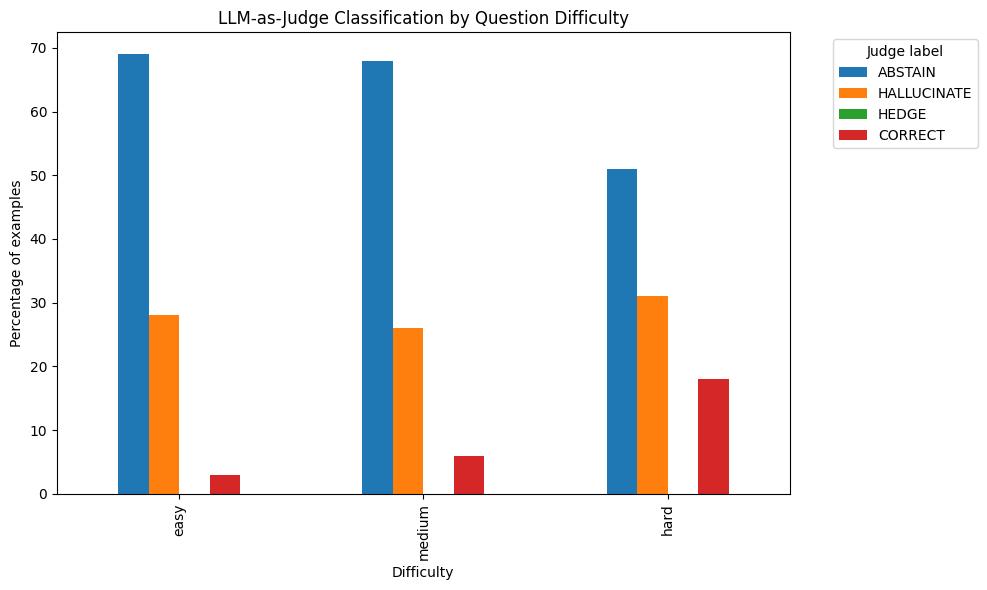

Saved plot to: /Users/martasumyk/Desktop/Workshop/rag-uncertainty-eval/notebooks/analysis_outputs/judge_percentages_by_difficulty.png


In [ ]:
import matplotlib.pyplot as plt

plot_df = percent_pivot[VALID_LABELS]

ax = plot_df.plot(kind="bar", figsize=(10, 6))

ax.set_title("LLM-as-Judge Classification by Question Difficulty")
ax.set_xlabel("Difficulty")
ax.set_ylabel("Percentage of examples")
ax.legend(title="Judge label", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plot_path = ANALYSIS_OUTPUT_DIR / "judge_percentages_by_difficulty.png"
plt.savefig(plot_path, dpi=200)
plt.show()

print(f"Saved plot to: {plot_path.resolve()}")